In [8]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import multivariate_normal
from sklearn.mixture import GaussianMixture
import sys
if not '../..' in sys.path:
    sys.path.append('../..')
    sys.path.append('..')

from analysis import analysis, model

mpl.rcParams.update(mpl.rcParamsDefault)
mpl.rcParams.update({'axes.labelsize': 16})
mpl.rcParams.update({'figure.figsize': (16*0.8,9*0.8)})
mpl.rcParams.update({'axes.facecolor': "white"})
mpl.rcParams.update({'lines.marker': "+"})
mpl.rcParams.update({'lines.linestyle': ""})
mpl.rcParams.update({"axes.spines.left":   True})
mpl.rcParams.update({"axes.spines.bottom": True})
mpl.rcParams.update({"axes.spines.top":    False})
mpl.rcParams.update({"axes.spines.right":  False})

image_path = Path("/Users/spencer/phd/phd/images/more_results/gmms/")

%matplotlib inline

# check lognormal stats

- come up with mean and covariance
- sample from multivar gaussian with these moments
- exp transform the samples elementwise -- these are lognormal samples! (log is normal)
- compute analytic lognormal mean and covariance
- numerically compute lognormal mean and covar (sample mean and covar)

In [9]:
def is_spd(x):
    return np.all(np.linalg.eigvals(x) > 0) and np.all(x == x.T)

(64,) (64, 64)
True


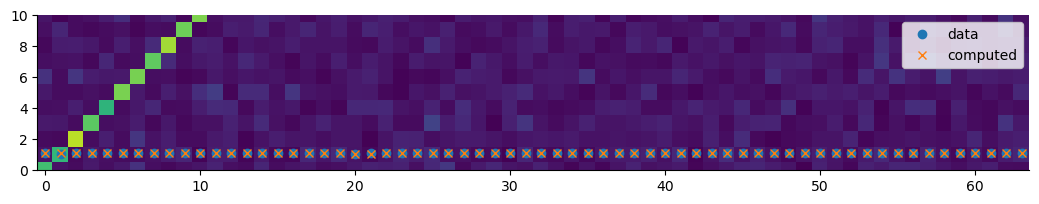

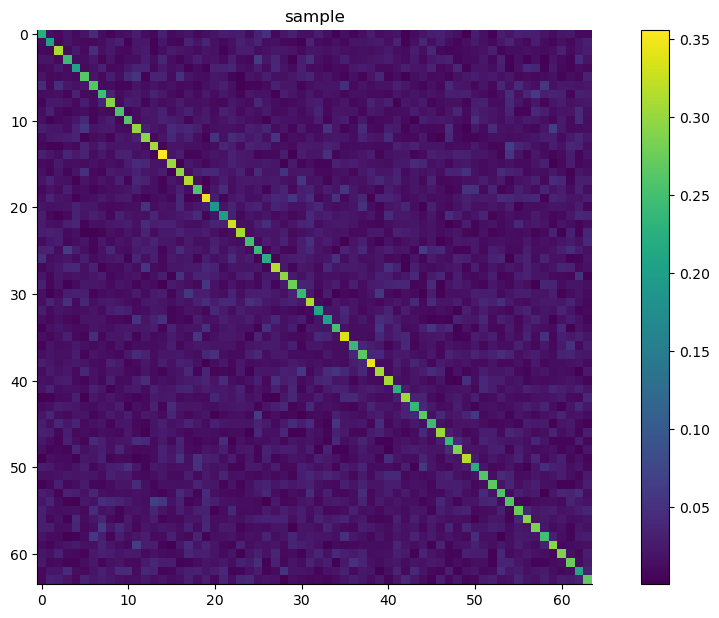

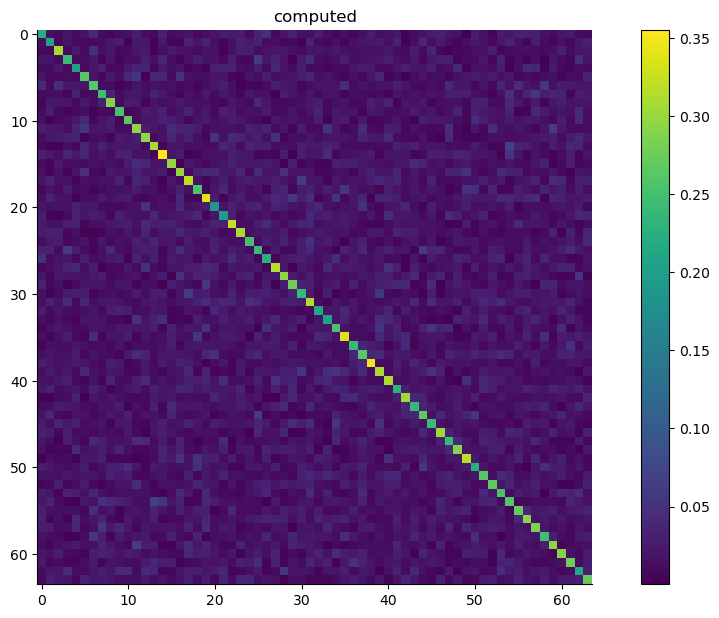

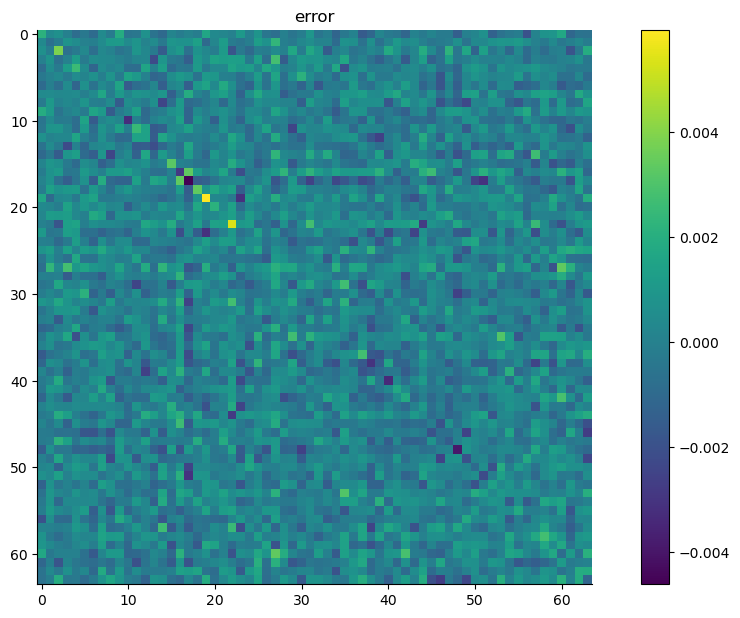

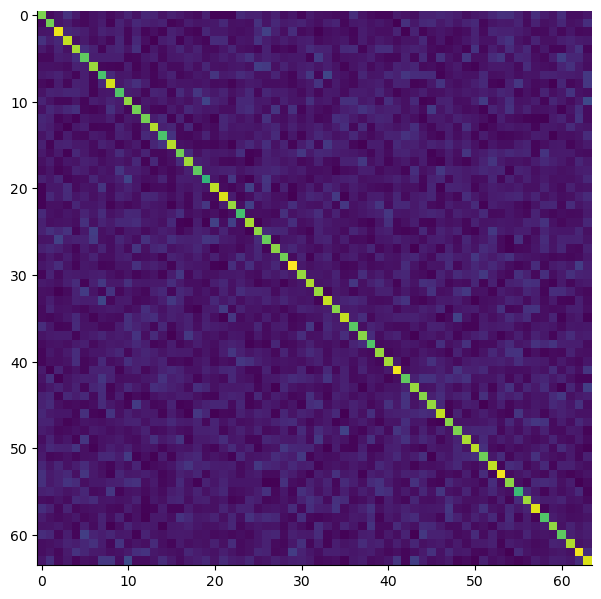

In [10]:
# https://stats.stackexchange.com/questions/214997/multivariate-log-normal-probabiltiy-density-function-pdf

p = 64
mean = np.zeros(p)
covariance = np.abs(np.eye(p)*0.1 + np.random.normal(size=(p,p))*0.01)
covariance += covariance.T

print(mean.shape, covariance.shape)

fig, ax = plt.subplots(1,1)
ax.imshow(covariance)

print(is_spd(covariance))

In [11]:
mixture_model = GaussianMixture(n_components=1)
mixture_model.means_ = mean.reshape(1,p)
mixture_model.covariances_ = covariance.reshape(1,p,p)
mixture_model.weights_ = np.ones(1).reshape(1)

print(mixture_model.means_.shape)
print(mixture_model.covariances_.shape)
print(mixture_model.weights_.shape)

N = 100000
normal_samples = mixture_model.sample(n_samples=N)[0]
normal_samples.shape

(1, 64)
(1, 64, 64)
(1,)


(100000, 64)

In [12]:
lognormal_samples = np.exp(normal_samples)
print(np.any(np.isnan(lognormal_samples)))
sample_lognormal_mean = np.mean(lognormal_samples, axis=0)
sample_lognormal_cov = np.cov(lognormal_samples.T)

False


In [13]:
computed_log_mean = analysis.make_lognormal_mean(mean.reshape(-1,1),covariance)
computed_log_cov = analysis.make_lognormal_covariance(mean.reshape(-1,1),covariance)

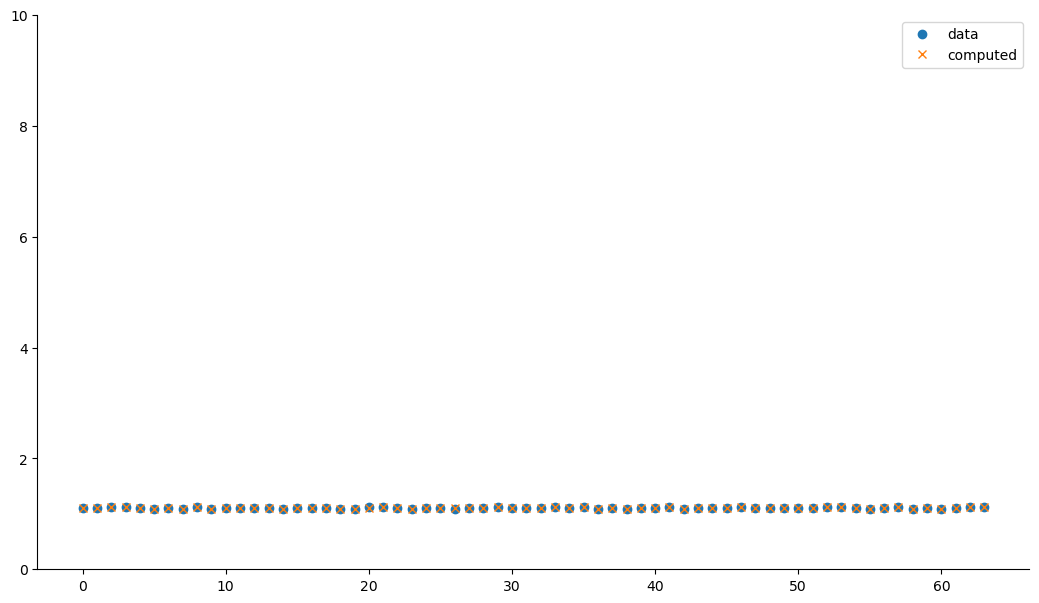

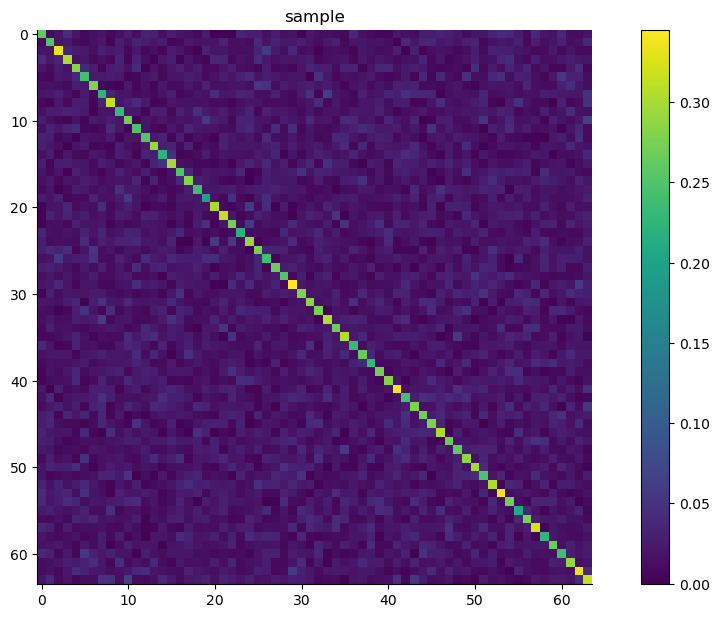

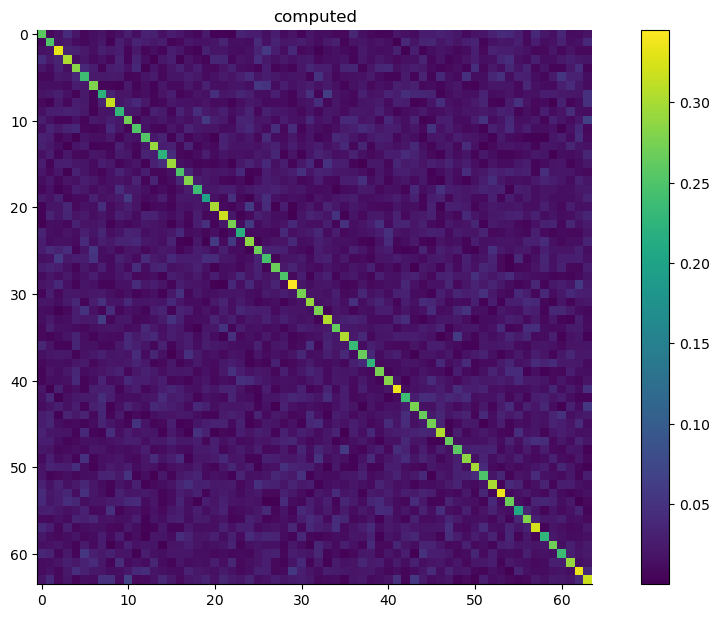

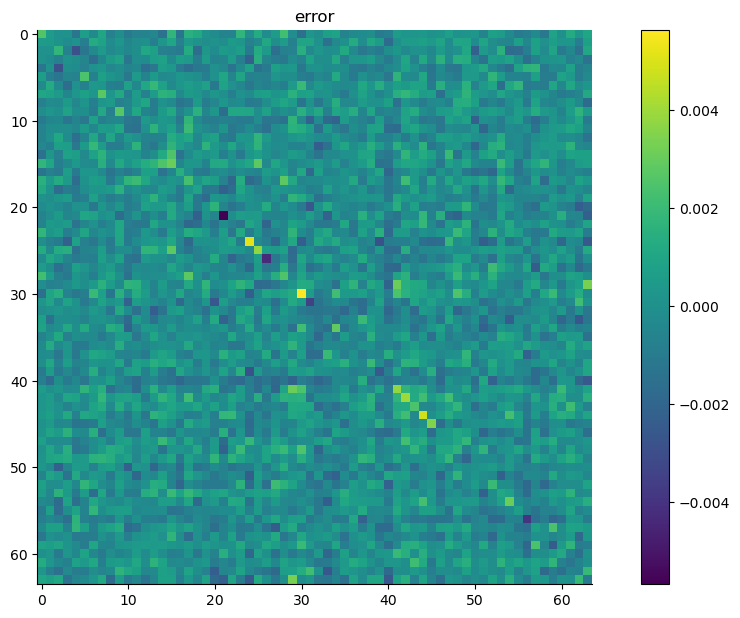

In [14]:
plt.plot(sample_lognormal_mean,"o",label="data")
plt.plot(computed_log_mean,"x",label="computed")
plt.ylim([0,10])
plt.legend()

plt.figure()
plt.title("sample")
plt.imshow(sample_lognormal_cov)
plt.colorbar()

plt.figure()
plt.title("computed")
plt.imshow(computed_log_cov)
plt.colorbar()

plt.figure()
plt.title("error")
plt.imshow(sample_lognormal_cov - computed_log_cov)
plt.colorbar()

In [16]:
decoder = np.random.normal(size=(2,p))

(-20.0, 20.0)

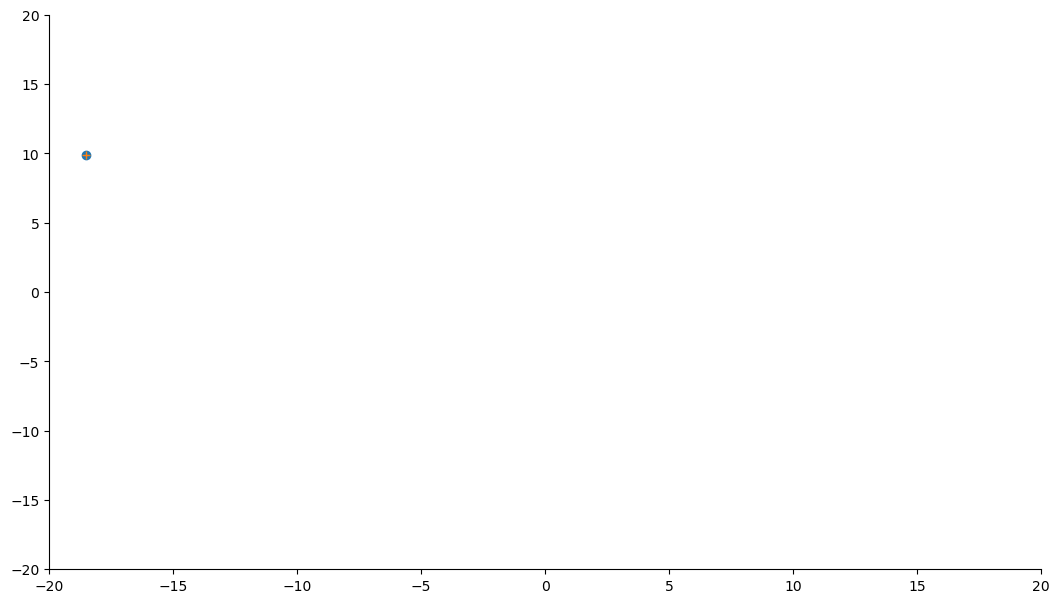

In [29]:
decoded_sample_mean = (decoder @ sample_lognormal_mean).reshape(-1)
decoded_computed_mean = (decoder @ computed_log_mean).reshape(-1)
decoded_sample_mean.shape, decoded_computed_mean.shape

plt.plot(decoded_computed_mean[0],decoded_computed_mean[1],"o")
plt.plot(decoded_sample_mean[0],decoded_sample_mean[1],"+")

plt.xlim([-20,20])
plt.ylim([-20,20])

In [75]:
def lognormal_pdf(mean, covariance, y):
    assert y.shape == mean.shape, (y.shape, mean.shape)
    assert covariance.shape[0] == covariance.shape[1], covariance.shape
    assert covariance.shape[0] == y.shape[0], (covariance.shape, y.shape)
    p = y.shape[0]
    a = (2*np.pi)**(-p/2)
    b = np.linalg.det(covariance)**(-0.5)
    c = np.product(1/y)
    d = np.log(y)-mean
    return a*b*c*np.exp(-0.5*d.T @ np.linalg.inv(covariance) @ d)

lognormal_pdf(mean,covariance,np.ones(p)*10)

2.0642990134938587e-128

In [215]:
x = np.meshgrid(*[np.linspace(0,10,100).T for _ in np.arange(p)])
np.asarray(x).shape

(2, 100, 100)

In [220]:
covariance.shape

(2, 2)

In [336]:
# vec_lognormal_pdf = np.vectorize(lognormal_pdf) #, signature='(n,m,m)->(m,m)')
# vec_lognormal_pdf(mean, covariance, np.asarray(x))

# print(result)
# fig, ax = plt.subplots(1)
# ax.contour(x, y, vec_lognormal_pdf(x, y))
# plt.show()

[Exponential of MoG is Mo(Lognormal)!](https://stats.stackexchange.com/questions/135307/distribution-of-the-exponential-of-a-mixture)

so the PDF is just the mixture of the PDFs?

# sample, project, histogram

In [240]:
import scipy.stats as st

In [ ]:
subjects = analysis.load_subjects()

In [315]:
def plot_contour_from_samples(samples, nbins, ax):
    x, y = samples[0], samples[1]

    nbins = 20
    bins = (np.linspace(-2, 2, nbins, endpoint=True),) * 2

    # ax.hist2d(x, y, bins=bins, cmin=1)

    HH, xe, ye = np.histogram2d(x, y, bins=bins)
    grid = HH.transpose()

    # compute bin midpoints
    midpoints = (xe[1:] + xe[:-1])/2, (ye[1:] + ye[:-1])/2
    # cs = ax.contourf(*midpoints, grid, levels=2, extend='max', cmap='plasma', alpha=0.5, zorder=100)
    ax.contour(*midpoints, grid, levels=1, zorder=100)
    # sample_mean = np.mean(normal_samples,axis=1)
    # ax.plot(sample_mean[0],sample_mean[1],"o")

def kde_plot(samples, ax):
    # xmin, xmax = ax.get_xlim()
    # ymin, ymax = ax.get_ylim()
    xmin, xmax = np.min(samples[:,0]), np.max(samples[:,0])
    ymin, ymax = np.min(samples[:,1]), np.max(samples[:,1])

    # Peform the kernel density estimate
    xx, yy = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]
    positions = np.vstack([xx.ravel(), yy.ravel()])

    kernel = st.gaussian_kde(samples.T)
    f = np.reshape(kernel(positions).T, xx.shape)

    # Contour plot
    cset = ax.contour(xx, yy, f, colors='k', levels=np.array([0.0, .5, 1.0, 1.5]))

    # Label plot
    ax.clabel(cset, inline=1, fontsize=10)

    return f

In [323]:
import seaborn as sns
import pandas as pd

from matplotlib import colormaps
cmap = colormaps['magma']

%matplotlib inline
%matplotlib widget

/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn

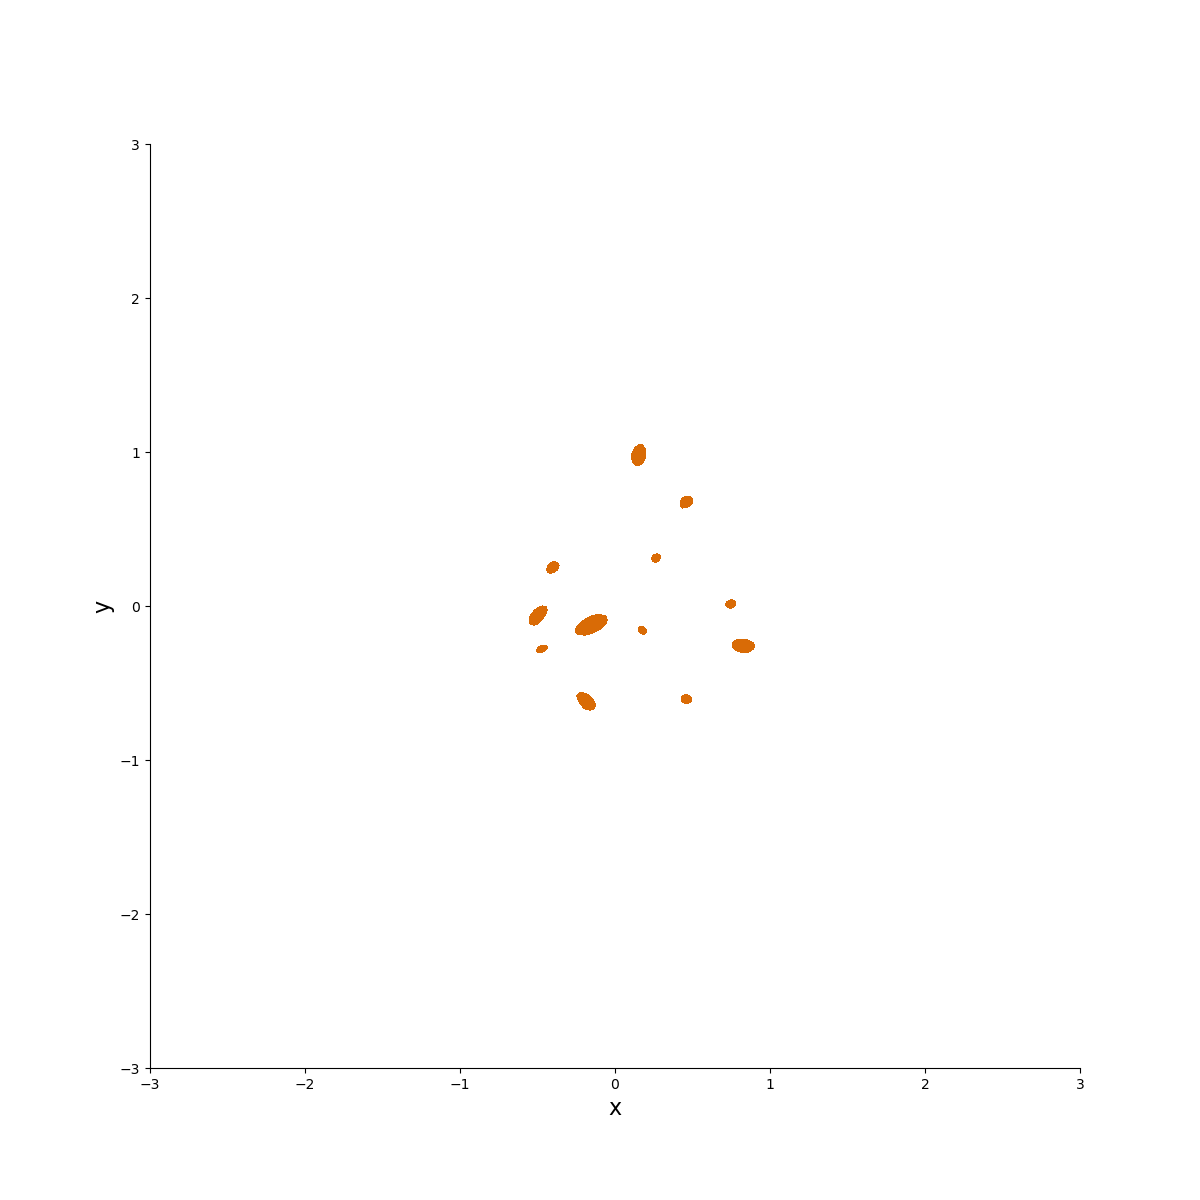

In [339]:
subject_idx = 16
subject_model = model.load_log_trial_models(subject_idx)[-1]
decoder = subjects[subject_idx].decoder[-2:,:]

fig, ax = plt.subplots(1,1,figsize=(12,12))
ax.set_xlim([-3,3])
ax.set_ylim([-3,3])
N = 15000
for i in range(12):
    g = GaussianMixture(n_components=1)
    g.means_ = subject_model.means_[i].reshape(1,64)
    g.covariances_ = subject_model.covariances_[i].reshape(1,64,64)
    g.weights_ = subject_model.weights_[i].reshape(1)
    lognormal_samples = np.exp(g.sample(N)[0])
    decoded_samples = decoder @ lognormal_samples.T
    # p = ax.plot(decoded_samples[0],decoded_samples[1],'.',alpha=0.1)
    # f = kde_plot(decoded_samples.T, ax)
    data = pd.DataFrame(decoded_samples.T,columns=['x','y'])
    sns.kdeplot(data, x='x', y='y', levels=[0.95,1.0], fill='k', ax=ax, color=p[0].get_color())
    
# stack = np.load("../subject_filtered_movement_stacks.npy")[subject_idx]
# decoder = subjects[subject_idx].decoder[-2:,:]
# samples = decoder @ stack.transpose(0,1,3,2).reshape(-1,64).T
# decoder = subjects[subject_idx].decoder[-2:,:]

# fig, ax = plt.subplots(1,1,figsize=(12,12))
# ax.set_xlim([-3,3])
# ax.set_ylim([-3,3])
# ax.plot(samples[0],samples[1],".",markersize=4,color='k',alpha=0.1,zorder=0)

# sample and project probabilities

- grid of positive points in N-d (for lognormal) : {y}
- compute lognormal values : f(y) = {v}
- project the y grid onto the plane : Ay = {x}
- pair values of x points with values : (y,v) --> (x,v)
- contour plot (x,v)

In [157]:
# ambient dimension
N = 3
# N to 2 decoder
decoder = np.random.normal(loc=0,scale=1,size=(2,N))

# number of grid points per axis
m = 25
X = np.asarray(np.meshgrid(*[np.linspace(0.01,2,m,endpoint=True) for _ in range(N)]))
X_pairs = X.reshape(N,-1)
print(X_pairs.shape)

# stats
mean = np.ones(shape=(N,))
covariance = np.eye(N)

(3, 15625)


In [158]:
# g = multivariate_normal(mean,cov=covariance)
# probabilities = np.array([g.pdf(x) for x in X_pairs.T])
probabilities = np.array([lognormal_pdf(mean.reshape(-1,1), covariance, yy.reshape(-1,1)) for yy in X_pairs.T]).reshape(-1)
print(probabilities.shape)

(15625,)


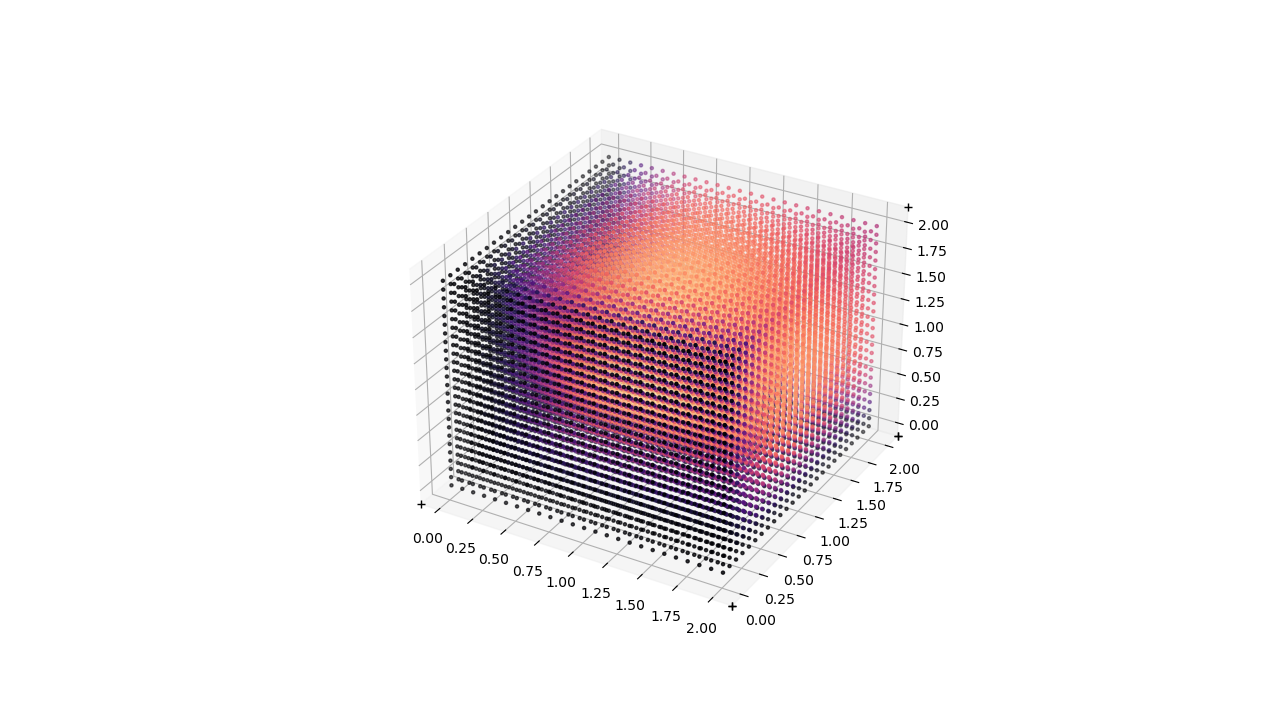

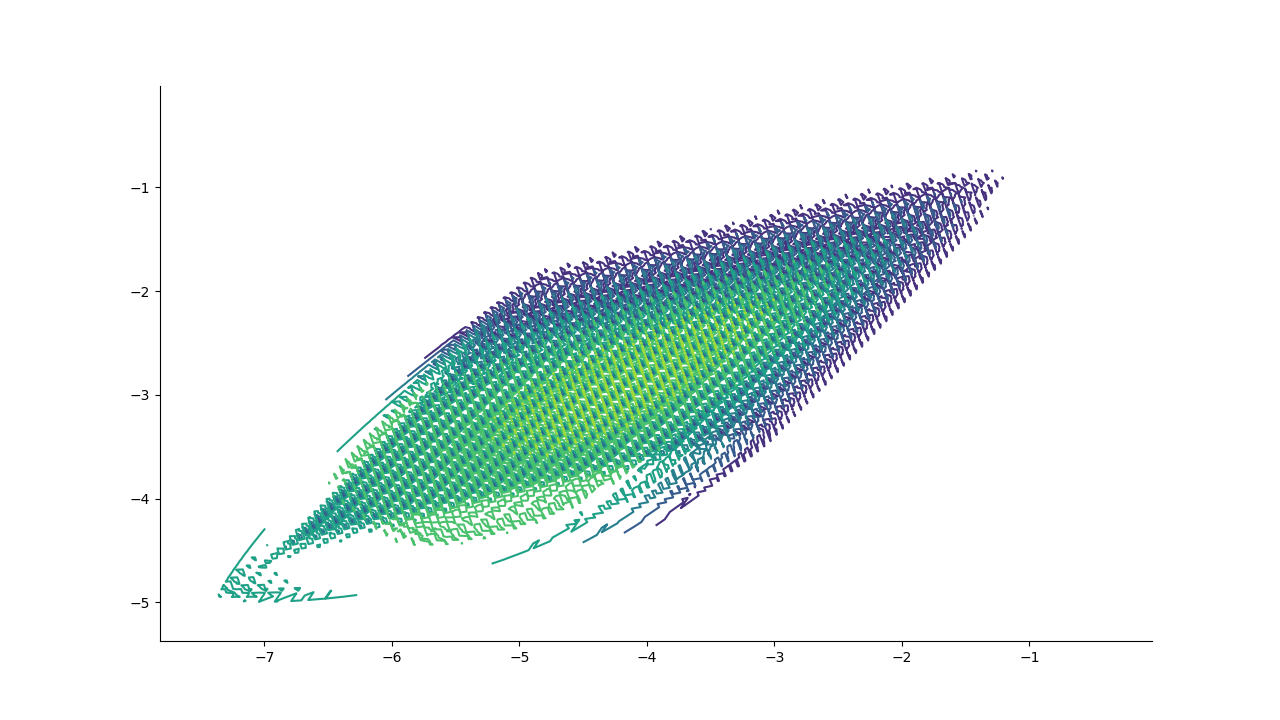

In [160]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(X_pairs[0], X_pairs[1], X_pairs[2], marker=".", color=cmap(probabilities/np.max(probabilities)))

X_decoded = decoder @ X_pairs

fig = plt.figure()
ax = fig.add_subplot()
# ax.scatter(X_decoded[0], X_decoded[1], marker=".", color=cmap(1-probabilities/np.max(probabilities)))
ax.tricontour(X_decoded[0], X_decoded[1], probabilities/np.max(probabilities))

# try interpolation on the decoder plane to make model contour plot

- collect the "data"
    - sample in R^n from a gaussian with mu and sigma -- big list of n-D points
    - use the lognormal PDF with n-D points to get probabilities (R^n --> R) -- these are the "values"

- find interpolation points on a plane through the ambient space
    - sample uniformly in 2D (meshgrid) -- list of 2D points
    - "undo" the decoder to project "back" into R^n (x = D_inv * y), x\inR^2, y\inR^n -- list of n-D points at which we interpolate

- interpolate the data+values and interpolate points with griddata

In [81]:
N = 3
# N to 2 decoder
decoder = np.random.normal(loc=0,scale=1,size=(2,N))
inverse_decoder = np.linalg.pinv(decoder)

print(decoder.shape)
print(inverse_decoder.shape)

(2, 3)
(3, 2)


In [87]:
# 2D points
m = 10
X = np.asarray(np.meshgrid(*[np.linspace(0,2,m,endpoint=True) for _ in range(2)]))
X_pairs = X.reshape(2,-1)
print(X_pairs.shape)

(2, 100)


In [88]:
np.all(X_pairs.reshape(2,m,m)==X)

True

(3, 100) (3, 10, 10)


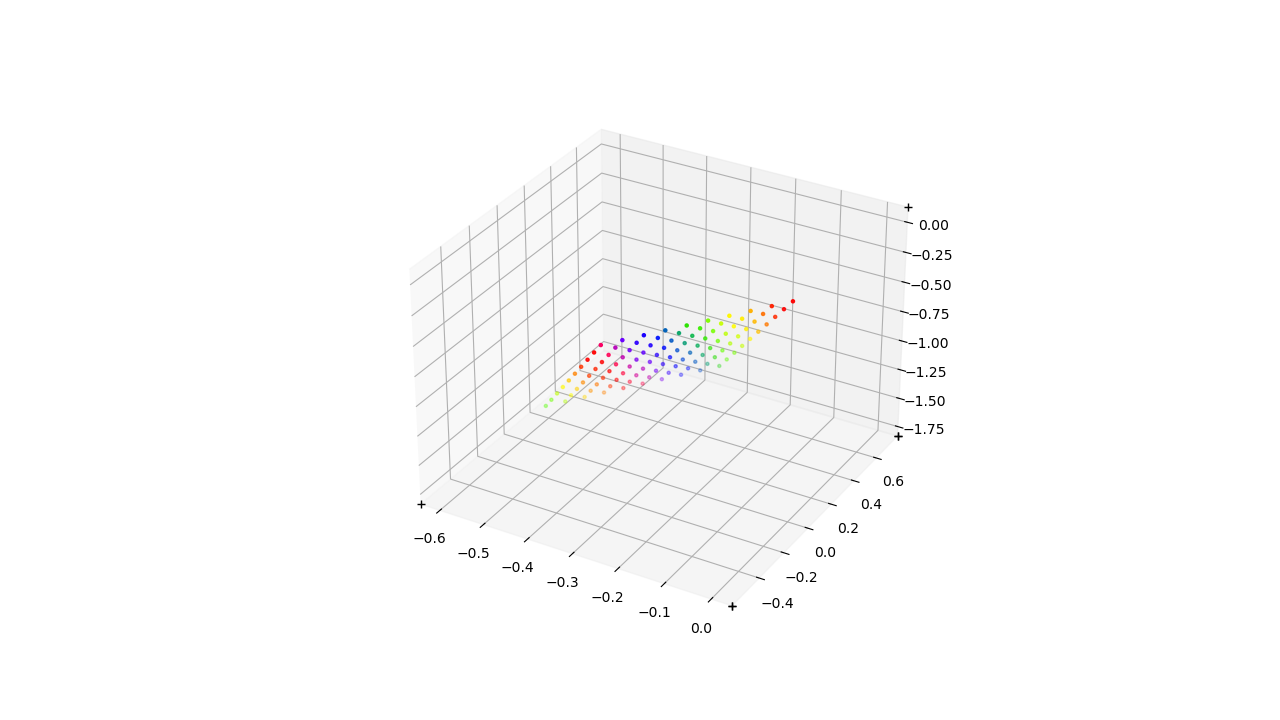

In [89]:
# projected into n-D
Xinv_pairs = inverse_decoder @ X_pairs
print(Xinv_pairs.shape, Xinv_pairs.reshape(N,m,m).shape)

# test for 3D
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(Xinv_pairs[0],Xinv_pairs[1],Xinv_pairs[2],marker=".",color=cmap(np.linspace(0,1,m**2,endpoint=True)))

# test recovering original 2D points
# Xrecover = decoder @ Xinv_pairs.reshape(3,-1)
# fig, ax = plt.subplots(1,1)
# ax.scatter(X_pairs[0],X_pairs[1],color="k",marker=".")
# ax.scatter(Xrecover[0],Xrecover[1],marker="+",alpha=0.5,color=cmap(np.linspace(0,1,2500,endpoint=True)))

In [79]:
# compute the probabilities for the plane points

probabilities = np.array([lognormal_pdf(mean.reshape(-1,1), covariance, yy.reshape(-1,1)) for yy in Xinv_pairs.T])
print(probabilities.shape)

/var/folders/dz/870p8tdx43j5527kzthy65zw0000gn/T/ipykernel_87420/2579047351.py:9: RuntimeWarning: invalid value encountered in log
  d = np.log(y)-mean


(10000, 1, 1)
